# AlphaJoin training plots

Reads `AlphaJoin1.0/learning_logs.out`, plots **Loss** and **Train/Test accuracy**.

- **Update plot** — on button click.
- **Update on file change** — check the box: the plot will redraw whenever the log file is written to (checked every 3 sec). If there are no changes to the log for **10 minutes**, auto-update stops automatically and the checkbox is cleared.

To run training in a separate terminal:
```bash
cd AlphaJoin1.0 && bash run_train.sh
```

In [ ]:
%pip install matplotlib ipywidgets -q


[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%matplotlib inline
import re
import time
import threading
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets

LOG_PATH = Path("ENTER HERE TRAINING LOG PATH")

def parse_learning_log(path):
    """Parse learning_logs.out -> steps, losses, test_accs, train_accs."""
    steps, losses, test_accs, train_accs = [], [], [], []
    if not path.exists():
        return steps, losses, test_accs, train_accs
    text = path.read_text(errors="replace")
    lines = text.strip().split("\n")
    i = 0
    while i < len(lines):
        # "[timestamp]  Epoch: N, Loss: X.XX"
        m = re.search(r"Epoch:\s*(\d+),\s*Loss:\s*([\d.]+)", lines[i])
        if m:
            step = int(m.group(1))
            loss = float(m.group(2))
            steps.append(step)
            losses.append(loss)
            # next line: correct_test total_test test_acc correct_train total_train train_acc
            if i + 1 < len(lines):
                parts = lines[i + 1].split()
                if len(parts) >= 6:
                    test_accs.append(float(parts[2]))
                    train_accs.append(float(parts[5]))
                else:
                    test_accs.append(None)
                    train_accs.append(None)
            i += 2
            continue
        i += 1
    return steps, losses, test_accs, train_accs

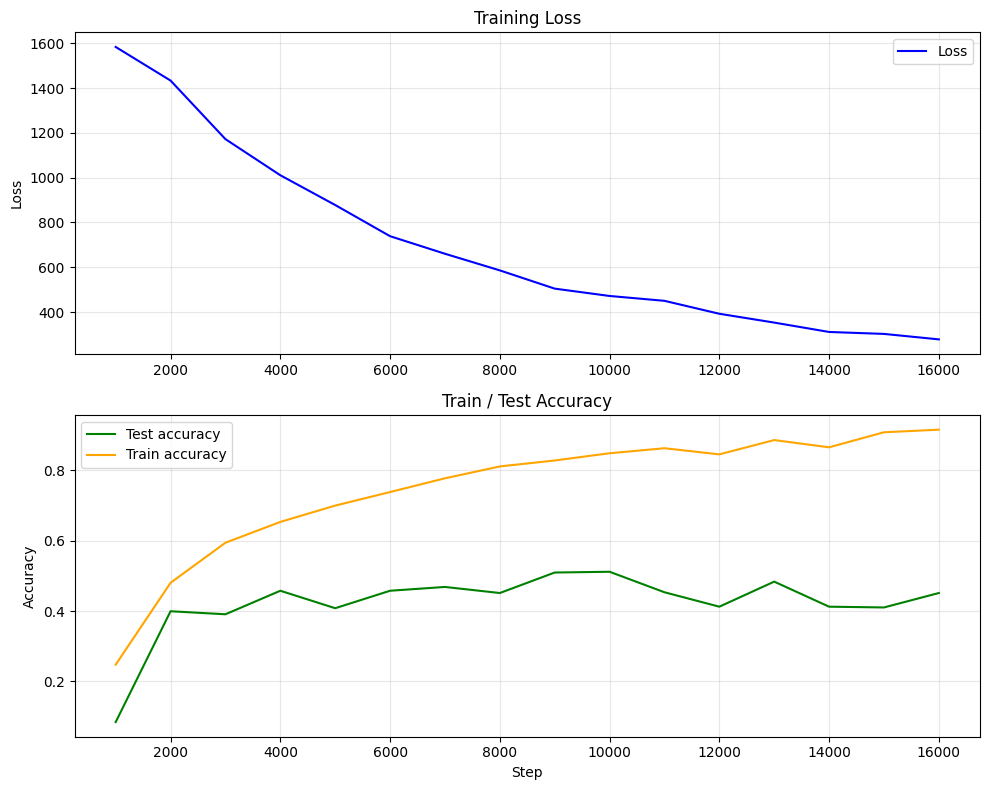

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

... (35 outputs left out)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

def draw_plots(ax1, ax2):
    steps, losses, test_accs, train_accs = parse_learning_log(LOG_PATH)
    ax1.clear()
    ax2.clear()
    if steps:
        ax1.plot(steps, losses, "b-", label="Loss")
        ax1.set_ylabel("Loss")
        ax1.set_title("Training Loss")
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        test_ok = [a for a in test_accs if a is not None]
        train_ok = [a for a in train_accs if a is not None]
        if len(steps) >= len(test_ok):
            ax2.plot(steps[: len(test_ok)], test_ok, "g-", label="Test accuracy")
        if len(steps) >= len(train_ok):
            ax2.plot(steps[: len(train_ok)], train_ok, color="orange", label="Train accuracy")
        ax2.set_xlabel("Step")
        ax2.set_ylabel("Accuracy")
        ax2.set_title("Train / Test Accuracy")
        ax2.legend()
        ax2.grid(True, alpha=0.3)
    else:
        ax1.set_title("Training Loss (no data)")
        ax2.set_title("Train / Test Accuracy (no data)")
    plt.tight_layout()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
out = widgets.Output()
last_mtime = [0.0]
last_change_time = [0.0]
NO_CHANGE_STOP_SEC = 600

def on_click(btn):
    with out:
        clear_output(wait=True)
        draw_plots(ax1, ax2)
        display(fig)
    if LOG_PATH.exists():
        last_mtime[0] = LOG_PATH.stat().st_mtime
    last_change_time[0] = time.time()

def check_file_and_redraw(_=None):
    try:
        mtime = LOG_PATH.stat().st_mtime
    except OSError:
        return
    if mtime > last_mtime[0]:
        last_mtime[0] = mtime
        last_change_time[0] = time.time()
        with out:
            clear_output(wait=True)
            draw_plots(ax1, ax2)
            display(fig)
    elif time.time() - last_change_time[0] >= NO_CHANGE_STOP_SEC:
        if timer_holder[0] is not None:
            timer_holder[0].cancel()
            timer_holder[0] = None
        auto_refresh.value = False


btn = widgets.Button(description="Update plot")
btn.on_click(on_click)

timer_holder = [None]

auto_refresh = widgets.Checkbox(description="Auto-refresh on file change", value=False)

def run_timer():
    check_file_and_redraw()
    if auto_refresh.value:
        t = threading.Timer(3.0, run_timer)
        timer_holder[0] = t
        t.start()

def on_auto_change(change):
    if change["new"]:
        last_change_time[0] = time.time()
        run_timer()
    else:
        if timer_holder[0] is not None:
            timer_holder[0].cancel()
            timer_holder[0] = None
auto_refresh.observe(on_auto_change, names="value")

draw_plots(ax1, ax2)
if LOG_PATH.exists():
    last_mtime[0] = LOG_PATH.stat().st_mtime
last_change_time[0] = time.time()

display(widgets.VBox([widgets.HBox([btn, auto_refresh]), out]))
with out:
    display(fig)